# 02 · Bulk cohorts, labels, unit table

Bulk RNA-seq (log2(TPM+1), 20,062 genes) with TLS labels (pathologist H&E / IHC; CNN labels train-only). Non-public cohorts (Internal lung, MGH) are read from `data/private/` when present and never shown per sample. The last section builds the unit table used for training (`data/processed/units.h5ad`).

In [1]:
import logging, os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
(ROOT / "results").mkdir(exist_ok=True)
logging.basicConfig(level=logging.INFO, format="%(asctime)s %(levelname)s %(name)s %(message)s",
                    handlers=[logging.StreamHandler(sys.stdout), logging.FileHandler(ROOT / "results" / "notebooks.log")],
                    force=True)
for noisy in ("anndata", "fsspec", "matplotlib", "PIL"):
    logging.getLogger(noisy).setLevel(logging.WARNING)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tls_model import pipeline
cfg = pipeline.load_config()
paths = {k: ROOT / v for k, v in cfg["paths"].items()}
FIG = paths["results"] / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Load (import from the raw archive only if the repo copy is missing)

In [2]:
from tls_model import io_bulk

if not (paths["bulk_public"] / io_bulk.LABELS_PRIMARY).exists():
    archive = os.environ.get("TLS_ARCHIVE_DIR")
    assert archive, "set TLS_ARCHIVE_DIR to the aggregated archive to import it once"
    io_bulk.import_archive(Path(archive), paths["bulk_public"], paths["bulk_private"])

private = paths["bulk_private"] if (paths["bulk_private"] / io_bulk.LABELS_PRIMARY).exists() else None
bulk = io_bulk.load_bulk(paths["bulk_public"], private)
bulk

AnnData object with n_obs × n_vars = 1473 × 20062
    obs: 'cancer_type', 'subtype', 'cohort', 'sample_id', 'patient_id', 'method', 'priority', 'n_annotators', 'iLA0', 'iLA1', 'iLA2', 'bLA0', 'bLA1', 'bLA2', 'nLA0', 'nLA1', 'nLA2', 'iTLS', 'bTLS', 'nTLS', 'TLS_count', 'TLS_count_scope', 'TLS_mature_count', 'LA0_tumor_count', 'tumor_area_mm2', 'TLS_density_per_mm2', 'TLS_area_percent', 'TLS_status', 'maturity_status', 'has_maturity', 'has_expression', 'excluded', 'patient', 'tls_any', 'tls_mature', 'label_source', 'unit', 'platform'
    layers: None (.X)

## Class balance per cohort (aggregates only)

In [3]:
obs = bulk.obs
summary = obs.groupby("cohort").agg(
    n=("tls_any", "size"), tls_pos=("tls_any", "sum"),
    maturity_known=("tls_mature", "count"), mature=("tls_mature", "sum"),
    pathologist=("label_source", lambda s: int((s == "pathologist").sum())),
    cnn=("label_source", lambda s: int((s == "cnn").sum())),
)
summary["role"] = np.where(summary.index.isin(cfg["cohorts"]["ood"]), "OOD (locked)", "train/test")
summary.to_csv(paths["results"] / "bulk_cohorts.tsv", sep="\t")
summary

,n,tls_pos,maturity_known,mature,pathologist,cnn,role
cohort,,,,,,,
CPTAC-PAAD,129,54.0,54,11.0,129,0,OOD (locked)
CPTAC-ccRCC,86,25.0,0,0.0,86,0,train/test
Internal_lung,47,17.0,0,0.0,47,0,OOD (locked)
MGH_LUAD_DagogoJack,12,9.0,9,1.0,12,0,train/test
TCGA-BRCA,420,203.0,89,9.0,153,267,train/test
TCGA-KIRC/KIRP/KICH,210,23.0,0,0.0,210,0,train/test
TCGA-LUAD,451,345.0,158,21.0,221,230,train/test
TCGA-PAAD,118,89.0,89,17.0,118,0,train/test


## Label ceiling: agreement of TLS +/- sources on TCGA-LUAD

No model can be judged above the agreement of its own labels.

In [4]:
long_table = pd.read_csv(paths["bulk_public"] / io_bulk.LABELS_LONG, sep="\t")
ceiling = pipeline.label_ceiling(long_table, "TCGA-LUAD")
ceiling.to_csv(paths["results"] / "label_ceiling_luad.tsv", sep="\t", index=False)
ceiling

,source_a,source_b,n,agreement,kappa
0,HookNet-TLS_a#3,HookNet-TLS_b#4,431,0.844548,0.198373
1,HookNet-TLS_a#3,pathologist_HE#1,165,0.769697,0.387695
2,HookNet-TLS_a#3,pathologist_HE#2,197,0.817259,0.514313
3,HookNet-TLS_b#4,pathologist_HE#1,159,0.754717,0.195407
4,HookNet-TLS_b#4,pathologist_HE#2,188,0.771277,0.244486
5,pathologist_HE#1,pathologist_HE#2,139,0.985612,0.964368


## Cohort structure (public cohorts only): PCA of log2(TPM+1)

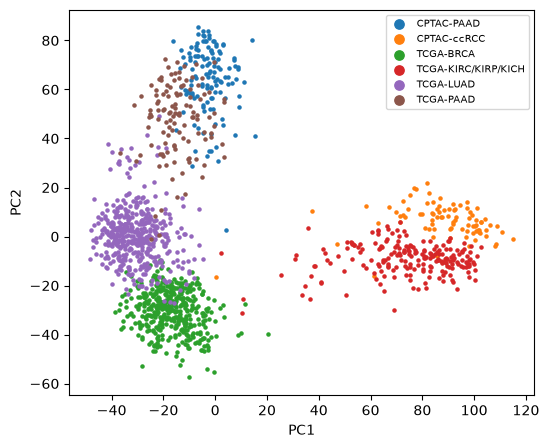

In [5]:
from sklearn.decomposition import PCA

public = bulk[~bulk.obs["cohort"].isin(io_bulk.PRIVATE_COHORTS)]
X = np.asarray(public.X)
top = np.argsort(-X.std(axis=0))[:2000]
pcs = PCA(n_components=2, random_state=0).fit_transform(X[:, top] - X[:, top].mean(axis=0))
fig, ax = plt.subplots(figsize=(6, 5))
for cohort in sorted(public.obs["cohort"].unique()):
    m = (public.obs["cohort"] == cohort).to_numpy()
    ax.scatter(pcs[m, 0], pcs[m, 1], s=5, label=cohort)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(fontsize=7, markerscale=3)
fig.savefig(FIG / "02_bulk_pca.png", dpi=120)

## Unit table (bulk + Visium spots / aggregates / sections)

Splits (patient-grouped), label-free gene filter and the frozen-only platform offset are fitted on TRAIN only. Set `REBUILD = True` to force a rebuild.

In [6]:
from tls_model import prepare

REBUILD = False
if REBUILD or not (paths["processed"] / "units.h5ad").exists():
    units, meta = prepare.prepare_units(cfg, ROOT)
else:
    units, meta = prepare.load_units(cfg, ROOT)
print(units.shape, "| kept genes:", len(meta["genes"]), "| shared genes:", meta["n_shared_genes"])
units.obs.groupby(["kind", "split", "unit"], observed=True).size().unstack(fill_value=0)

(48310, 5049) | kept genes: 5049 | shared genes: 16788


unit          agg7  agg19  bulk  section   spot
kind   split                                   
bulk   ood       0      0   176        0      0
       test      0      0   162        0      0
       train     0      0  1135        0      0
visium test      0      0     0        7  25206
       train  7200   7200     0       24   7200

In [7]:
units.obs.groupby(["kind", "split"], observed=True).agg(
    units=("tls_any", "size"), tls_any=("tls_any", "sum"), maturity_known=("tls_mature", "count"), mature=("tls_mature", "sum"))

units  tls_any  maturity_known  mature
kind   split                                        
bulk   ood      176     71.0              54    11.0
       test     162     80.0              70     9.0
       train   1135    614.0             275    39.0
visium test   25213    380.0              75    18.0
       train  21624   7605.0            2349  1153.0

In [8]:
sections = pd.DataFrame(meta["sections"])
print(sections.groupby(["split", "source", "protocol"]).size())
print("test patients:", sorted(sections.loc[sections["split"] == "test", "patient"].unique()))

split  source     protocol
test   GSE175540  ffpe         4
                  frozen       1
       USZ        ffpe         2
train  GSE175540  ffpe         7
                  frozen      11
       USZ        ffpe         6
dtype: int64
test patients: ['GSE175540_c_21', 'GSE175540_c_34', 'GSE175540_c_39', 'GSE175540_c_57', 'GSE175540_c_7', 'USZ_KC1', 'USZ_LC5']
